# YOLO11m 베이스라인

노션 칸반 '진행 중' 항목 중 YOLO11m 베이스라인 기준을 따릅니다. 저장소의 `.py` 코드는 쓰지 않고 이 노트북 안에서 모두 작성합니다.

1. Colab 연결 (GPU 확인, 저장소·패키지 준비)
2. 설정
3. 경로와 장치
4. 데이터 준비 (원본 JSON → 라벨 보정 → combo 5 fold 분할 → YOLO 형식)
5. 학습 (MuSGD, early stopping 5, best.pt는 mAP75-95 기준, epoch별 시간 tqdm)
6. 평가 (mAP75-95 · Precision · Recall · 추론속도)
7. 혼동행렬 conf 0.001 vs 0.25
8. 실패 사례 시각화

**실행 순서**
- 로컬: `SMOKE = True`로 위에서부터 실행해 동작만 확인합니다 (1 epoch, 학습 사진 10%).
- Colab: 커널을 Colab GPU 서버로 고르고, `SMOKE = False`로 바꾼 뒤 위에서부터 실행합니다.

## 1. Colab 연결

GPU는 코드가 아니라 **커널 선택**으로 받습니다. VS Code 노트북 오른쪽 위 커널 선택 → **Colab** → 새 서버 → **GPU**(T4 등).

Colab이면 이 셀이 아래를 준비하고, 로컬에서는 아무것도 하지 않습니다.

- GPU 확인 (없으면 멈춤)
- 저장소 받기: 보정 기록 csv(`data/processed/*.csv`)와 폴더 구조를 쓰려고 받습니다. 저장소의 `.py`는 import하지 않습니다.
- ultralytics 설치: 로컬 `uv.lock`과 같은 8.4.182

결과는 노트북 출력으로 남깁니다. Colab 서버의 파일(best.pt 등)은 런타임이 끝나면 사라집니다.

In [27]:
import os
from pathlib import Path

# VS Code에서 Colab 커널에 붙으면 COLAB_RELEASE_TAG가 없을 수 있어 /content 폴더도 본다
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or Path("/content").is_dir()

if IN_COLAB:
    import torch

    assert torch.cuda.is_available(), "GPU가 아닙니다. 커널을 Colab GPU 서버로 다시 고르세요."
    print(torch.cuda.get_device_name(0))

    REPO_DIR = Path("/content/pill-bbox")
    if not REPO_DIR.exists():
        !git clone -q -b main https://github.com/def-uk/pill-bbox.git {REPO_DIR}
    os.chdir(REPO_DIR)

    %pip install -q ultralytics==8.4.182

print(f"Colab: {IN_COLAB}  /  작업 폴더: {Path.cwd()}")

Tesla T4
Colab: True  /  작업 폴더: /content/pill-bbox


## 2. 설정

모든 모델 베이스라인에 같게 적용하는 값입니다. 바꾸지 않습니다.

In [28]:
# ===== 베이스라인 공통 설정 (노션 1번 항목) =====
MODEL = "yolo11m.pt"  # COCO 사전학습 가중치에서 시작하는 전체 파인튜닝 (freeze 없음)
SEED = 42
EPOCHS = 30
PATIENCE = 5  # 검증 mAP75-95가 5 epoch 동안 오르지 않으면 학습을 멈춘다
BATCH = 16
IMGSZ = 640
OPTIMIZER = "MuSGD"
LR0 = 0.001
EVAL_CONF = 0.001  # 평가(mAP 계산)에 쓰는 신뢰도 하한
PLOT_CONF = 0.25  # 비교 그림에 박스를 그릴 때 쓰는 신뢰도 하한. 평가용과 구분한다
CM_CONF = 0.25  # 혼동행렬에 쓰는 신뢰도 하한. 0.001과 비교한 뒤 고정 (7단계)
NMS_IOU = 0.5  # YOLO11은 NMS 후처리를 쓰므로 이 값이 실제로 적용된다
MAX_DET = 4  # 사진 한 장에서 남기는 최대 박스 수 (데이터의 사진당 알약은 3–4개)

# ===== 분할 (노션 2번 항목) =====
# 알약 조합 단위로 나눈다. 같은 조합을 다른 각도로 찍은 사진이 train·val에 갈라지지 않게 한다
SPLIT_UNIT = "combo"
N_FOLDS = 5  # 조합을 5묶음으로 나눠 fold마다 한 묶음(약 20%)을 val로 쓴다
FOLD = 0
RARE_MAX_BOXES = 5  # 박스가 이 수 이하인 약이 들어간 조합은 val에 넣지 않고 train에 고정한다

# ===== 실행 =====
SMOKE = False  # True: 1 epoch, 학습 사진 10%로 동작만 확인. Colab GPU 본 학습은 False

## 3. 경로와 장치

원본 데이터를 읽는 곳과 이 노트북이 결과를 쓰는 곳입니다. 결과 폴더는 모두 Git에서 제외되는 위치(`data/processed/`, `runs/`)에 둡니다.

In [29]:
import random

import numpy as np
import pandas as pd
import torch

# 노트북이 어느 폴더에서 열려도 pyproject.toml이 있는 곳을 프로젝트 루트로 쓴다
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()
)
# ultralytics는 yolo11m.pt 등 가중치를 현재 폴더에 받으므로 프로젝트 루트에서 실행한다
os.chdir(PROJECT_ROOT)
NAME = "yolo11m_kwon"

# 읽기: 원본 (고치지 않는다)과 보정 기록
RAW_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_IMG_DIR = RAW_DIR / "train_images"
TRAIN_ANN_DIR = RAW_DIR / "train_annotations"
TEST_IMG_DIR = RAW_DIR / "test_images"
CORRECTION_DIR = PROJECT_ROOT / "data" / "processed"

# 쓰기: 데이터 준비 결과 (라벨 표, 분할 목록, YOLO 형식 이미지·라벨, data.yaml)
DATA_OUT_DIR = PROJECT_ROOT / "data" / "processed" / NAME
YOLO_DIR = DATA_OUT_DIR / f"yolo_{SPLIT_UNIT}_fold{FOLD}"
DATA_YAML = YOLO_DIR / "data.yaml"

# 쓰기: 학습·평가 결과 (가중치 best.pt·last.pt, results.csv, 그림)
RUNS_OUT_DIR = PROJECT_ROOT / "runs" / NAME
EXP = f"{'smoke_' if SMOKE else ''}{Path(MODEL).stem}_{OPTIMIZER}_lr{LR0:g}_{SPLIT_UNIT}_fold{FOLD}"
EXP_DIR = RUNS_OUT_DIR / EXP
WEIGHTS_DIR = EXP_DIR / "weights"


def get_device() -> str:
    """CUDA(Windows/Linux) > MPS(Mac) > CPU 순으로 쓸 수 있는 장치를 고른다."""
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


def set_seed(seed: int) -> None:
    """분할·학습이 다시 실행해도 같게 나오도록 난수를 고정한다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


DEVICE = get_device()
set_seed(SEED)
if not SMOKE and DEVICE != "cuda":
    raise RuntimeError(f"본 학습은 GPU에서 합니다(지금 {DEVICE}). 동작 확인은 SMOKE = True.")

print(f"장치: {DEVICE}  /  실험 이름: {EXP}")
pd.DataFrame(
    [
        ("읽기", "원본 train 이미지", TRAIN_IMG_DIR),
        ("읽기", "원본 train JSON", TRAIN_ANN_DIR),
        ("읽기", "원본 test 이미지", TEST_IMG_DIR),
        ("읽기", "보정 기록 csv", CORRECTION_DIR),
        ("쓰기", "데이터 준비 결과", DATA_OUT_DIR),
        ("쓰기", "YOLO 데이터셋", YOLO_DIR),
        ("쓰기", "data.yaml", DATA_YAML),
        ("쓰기", "학습·평가 결과", EXP_DIR),
        ("쓰기", "best.pt / last.pt", WEIGHTS_DIR),
    ],
    columns=["구분", "내용", "경로"],
).assign(있음=lambda df: df["경로"].map(Path.exists))

장치: cuda  /  실험 이름: yolo11m_MuSGD_lr0.001_combo_fold0


,구분,내용,경로,있음
0,읽기,원본 train 이미지,/content/pill-bbox/data/raw/train_images,True
1,읽기,원본 train JSON,/content/pill-bbox/data/raw/train_annotations,True
2,읽기,원본 test 이미지,/content/pill-bbox/data/raw/test_images,True
3,읽기,보정 기록 csv,/content/pill-bbox/data/processed,True
4,쓰기,데이터 준비 결과,/content/pill-bbox/data/processed/yolo11m_kwon,True
5,쓰기,YOLO 데이터셋,/content/pill-bbox/data/processed/yolo11m_kwon...,True
6,쓰기,data.yaml,/content/pill-bbox/data/processed/yolo11m_kwon...,True
7,쓰기,학습·평가 결과,/content/pill-bbox/runs/yolo11m_kwon/yolo11m_M...,False
8,쓰기,best.pt / last.pt,/content/pill-bbox/runs/yolo11m_kwon/yolo11m_M...,False


In [30]:
def show_outputs(root: Path, max_files: int = 10) -> pd.DataFrame:
    """결과 폴더 아래 파일을 폴더별로 몇 개씩 보여 준다. 저장이 제대로 됐는지 확인용."""
    if not root.exists():
        print(f"아직 없습니다: {root}")
        return pd.DataFrame()
    rows = []
    for folder in sorted({p.parent for p in root.rglob("*") if p.is_file()}):
        files = sorted(p for p in folder.iterdir() if p.is_file())
        name = str(folder.relative_to(root))
        for p in files[:max_files]:
            rows.append((name, p.name, f"{p.stat().st_size / 1024:.1f} KB"))
        if len(files) > max_files:
            rows.append((name, f"... 외 {len(files) - max_files}개", ""))
    print(f"{root}")
    return pd.DataFrame(rows, columns=["폴더", "파일", "크기"])


# 처음에는 비어 있다. 데이터 준비·학습 뒤에 다시 실행해 결과를 확인한다
show_outputs(DATA_OUT_DIR)

/content/pill-bbox/data/processed/yolo11m_kwon


,폴더,파일,크기
0,.,classes.csv,2.7 KB
1,.,labels.csv,99.9 KB
2,.,split_combo_s42.csv,17.2 KB
3,yolo_combo_fold0,data.yaml,0.9 KB
4,yolo_combo_fold0/images/train,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,1756.0 KB
5,yolo_combo_fold0/images/train,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,1635.2 KB
6,yolo_combo_fold0/images/train,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,1832.1 KB
7,yolo_combo_fold0/images/train,K-001900-016548-019607-033009_0_2_0_2_70_000_2...,1707.9 KB
8,yolo_combo_fold0/images/train,K-001900-016548-019607-033009_0_2_0_2_75_000_2...,1608.5 KB
9,yolo_combo_fold0/images/train,K-001900-016548-019607-033009_0_2_0_2_90_000_2...,1780.7 KB


## 4. 데이터 준비

### 4-1. 원본 확인

`data/raw`에 train 사진과 JSON이 있는지 봅니다. 없으면 여기서 멈춥니다.

In [31]:
if not (TRAIN_IMG_DIR.is_dir() and TRAIN_ANN_DIR.is_dir()):
    raise RuntimeError(f"원본 데이터가 없습니다: {RAW_DIR}")

print(f"train 사진 {len(list(TRAIN_IMG_DIR.glob('*.png')))}장")
print(f"train JSON {len(list(TRAIN_ANN_DIR.rglob('*.json')))}개")

train 사진 232장
train JSON 763개


### 4-2. 원본 JSON 읽기

JSON 하나에 사진 하나·알약 하나의 정보가 있습니다. 박스 한 개를 한 행으로 모읍니다. bbox는 원본 픽셀 기준 `[왼쪽 위 x, 왼쪽 위 y, 너비, 높이]`입니다.

In [32]:
import json

BOX = ["x", "y", "w", "h"]

rows = []
for path in sorted(TRAIN_ANN_DIR.rglob("*.json")):
    ann = json.loads(path.read_text(encoding="utf-8"))
    img = ann["images"][0]
    for a in ann["annotations"]:
        rows.append(
            {
                "file_name": img["file_name"],
                "width": img["width"],
                "height": img["height"],
                "category_id": a["category_id"],
                "dl_name": img["dl_name"],
                **dict(zip(BOX, a["bbox"], strict=True)),
            }
        )
raw_labels = pd.DataFrame(rows)

n_images = len(list(TRAIN_IMG_DIR.glob("*.png")))
print(f"박스 {len(raw_labels)}개, 클래스 {raw_labels['category_id'].nunique()}개")
print(f"라벨이 있는 사진 {raw_labels['file_name'].nunique()}장 / 원본 사진 {n_images}장")
raw_labels.head()

박스 763개, 클래스 56개
라벨이 있는 사진 232장 / 원본 사진 232장


,file_name,width,height,category_id,dl_name,x,y,w,h
0,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,1900,보령부스파정 5mg,644,845,189,190
1,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,1900,보령부스파정 5mg,148,241,181,181
2,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,976,1280,1900,보령부스파정 5mg,167,248,184,182
3,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,16548,가바토파정 100mg,144,799,239,239
4,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,16548,가바토파정 100mg,578,222,233,226


### 4-3. 라벨 보정 반영

원본 JSON은 고치지 않고, 보정 기록 csv를 읽어 라벨 표에만 반영합니다.

- `fixed_annotations.csv`: 위치가 틀린 박스의 수정 전·후 좌표 (5개)
- `added_annotations.csv`: 라벨이 빠진 알약 (8개)

반영한 뒤 두 가지를 검사합니다. 파일 이름의 조합(`K-코드1-코드2-...`)에 적힌 알약 수와 박스 수가 같은지, 박스가 사진 안에 있는지 봅니다.

In [33]:
fixed = pd.read_csv(CORRECTION_DIR / "fixed_annotations.csv")
added = pd.read_csv(CORRECTION_DIR / "added_annotations.csv")
labels = raw_labels.copy()

# 위치 수정: 파일·클래스·수정 전 좌표가 모두 같은 박스를 찾아 새 좌표로 바꾼다
for fix in fixed.itertuples():
    hit = (
        (labels["file_name"] == fix.file_name)
        & (labels["category_id"] == fix.category_id)
        & (labels[BOX] == [fix.old_x, fix.old_y, fix.old_w, fix.old_h]).all(axis=1)
    )
    if hit.sum() != 1:
        raise ValueError(f"수정할 박스를 하나로 찾지 못했습니다: {fix.file_name} {fix.category_id}")
    labels.loc[hit, BOX] = [fix.x, fix.y, fix.w, fix.h]

# 누락 추가: 사진 크기는 같은 사진의 다른 박스에서, 약 이름은 같은 클래스의 다른 박스에서 가져온다
size = labels.drop_duplicates("file_name").set_index("file_name")[["width", "height"]]
names = labels.drop_duplicates("category_id").set_index("category_id")["dl_name"]
new = added[["file_name", "category_id", *BOX]].join(size, on="file_name")
new["dl_name"] = new["category_id"].map(names)
if new.isna().any().any():
    missing = new[new.isna().any(axis=1)]
    raise ValueError(f"추가할 박스의 사진 크기나 약 이름을 찾지 못했습니다:\n{missing}")
labels = pd.concat([labels, new[labels.columns]], ignore_index=True)
labels = labels.sort_values(["file_name", "category_id"], ignore_index=True)
labels["combo"] = labels["file_name"].str.split("_").str[0]

# 검사
n_pills = labels.groupby("file_name")["combo"].first().str.count("-")  # K-a-b-c → 3개
n_boxes = labels.groupby("file_name").size()
outside = (
    (labels["x"] < 0)
    | (labels["y"] < 0)
    | (labels["x"] + labels["w"] > labels["width"])
    | (labels["y"] + labels["h"] > labels["height"])
    | (labels["w"] <= 0)
    | (labels["h"] <= 0)
)
print(f"박스 {len(raw_labels)}개 → 위치 수정 {len(fixed)}개, 추가 {len(new)}개 → {len(labels)}개")
print(f"알약 수와 박스 수가 다른 사진: {(n_pills != n_boxes).sum()}장 (0이어야 함)")
print(f"사진 밖으로 나간 박스: {outside.sum()}개 (0이어야 함)")

DATA_OUT_DIR.mkdir(parents=True, exist_ok=True)
labels.to_csv(DATA_OUT_DIR / "labels.csv", index=False, encoding="utf-8")
labels.head()

박스 763개 → 위치 수정 5개, 추가 8개 → 771개
알약 수와 박스 수가 다른 사진: 0장 (0이어야 함)
사진 밖으로 나간 박스: 0개 (0이어야 함)


,file_name,width,height,category_id,dl_name,x,y,w,h,combo
0,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,1900,보령부스파정 5mg,644,845,189,190,K-001900-016548-019607-029451
1,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,16548,가바토파정 100mg,144,799,239,239,K-001900-016548-019607-029451
2,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,19607,스토가정 10mg,657,287,155,150,K-001900-016548-019607-029451
3,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,29451,레일라정,108,218,392,264,K-001900-016548-019607-029451
4,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,1900,보령부스파정 5mg,148,241,181,181,K-001900-016548-019607-029451


### 4-4. 클래스 표

`category_id`(원본 약 번호)를 0부터 시작하는 YOLO 클래스 번호(`yolo_idx`)로 바꿉니다. `rare`는 박스가 5개 이하인 약입니다.

In [34]:
class_table = (
    labels.groupby("category_id")
    .agg(
        dl_name=("dl_name", "first"),
        n_boxes=("file_name", "size"),
        n_images=("file_name", "nunique"),
        n_combos=("combo", "nunique"),
    )
    .reset_index()
)
class_table.insert(0, "yolo_idx", range(len(class_table)))
class_table["rare"] = class_table["n_boxes"] <= RARE_MAX_BOXES
class_table.to_csv(DATA_OUT_DIR / "classes.csv", index=False, encoding="utf-8")

n_rare = class_table["rare"].sum()
print(f"클래스 {len(class_table)}개, 그중 박스 {RARE_MAX_BOXES}개 이하 {n_rare}개")
class_table.sort_values("n_boxes").head(20)

클래스 56개, 그중 박스 5개 이하 17개


,yolo_idx,category_id,dl_name,n_boxes,n_images,n_combos,rare
5,5,3743,알드린정,3,3,1,True
11,11,13395,써스펜8시간이알서방정 650mg,3,3,1,True
9,9,12247,아빌리파이정 10mg,3,3,1,True
8,8,12081,리렉스펜정 300mg/PTP,3,3,1,True
31,31,22362,맥시부펜이알정 300mg,3,3,1,True
28,28,21771,라비에트정 20mg,3,3,1,True
21,21,19552,트루비타정 60mg/병,3,3,1,True
16,16,16551,동아가바펜틴정 800mg,3,3,1,True
48,48,33009,신바로정,3,3,1,True
49,49,33208,에스원엠프정 20mg,3,3,1,True


### 4-5. combo 5 fold 분할

1. 희귀 약(박스 5개 이하)이 들어간 조합은 train에 고정합니다(`fold = -1`). val에만 들어가면 학습 때 한 번도 못 보기 때문입니다.
2. 나머지 조합을 seed로 섞은 뒤, 사진이 많은 조합부터 사진 수가 가장 적은 fold에 넣습니다. 그래서 fold마다 val 사진 수가 고르게 됩니다.
3. fold k는 k번 묶음을 val, 나머지를 train으로 씁니다.

In [35]:
rare_ids = class_table.loc[class_table["rare"], "category_id"]
pinned = set(labels.loc[labels["category_id"].isin(rare_ids), "combo"])
combo_images = labels.groupby("combo")["file_name"].nunique()
pool = combo_images.drop(list(pinned)).sample(frac=1, random_state=SEED)

fold_of = {}
fold_images = [0] * N_FOLDS
# stable 정렬이라 사진 수가 같은 조합끼리는 섞은 순서가 유지된다
for combo, n in pool.sort_values(ascending=False, kind="stable").items():
    k = int(np.argmin(fold_images))
    fold_of[combo] = k
    fold_images[k] += n

images = labels.groupby("file_name", as_index=False)["combo"].first()
images["fold"] = images["combo"].map(fold_of).fillna(-1).astype(int)  # -1: train 고정
images.to_csv(DATA_OUT_DIR / f"split_{SPLIT_UNIT}_s{SEED}.csv", index=False, encoding="utf-8")

rows = []
for k in range(N_FOLDS):
    is_val = labels["file_name"].isin(images.loc[images["fold"] == k, "file_name"])
    val_cls = set(labels.loc[is_val, "category_id"])
    train_cls = set(labels.loc[~is_val, "category_id"])
    rows.append(
        {
            "fold": k,
            "val 조합": labels.loc[is_val, "combo"].nunique(),
            "val 사진": labels.loc[is_val, "file_name"].nunique(),
            "val 사진 비율": labels.loc[is_val, "file_name"].nunique() / len(images),
            "val 박스": is_val.sum(),
            "val 클래스": len(val_cls),
            "val에만 있는 클래스": len(val_cls - train_cls),
        }
    )
print(f"조합 {len(combo_images)}개 = train 고정 {len(pinned)}개 + 5 fold로 나눈 {len(pool)}개")
pd.DataFrame(rows).style.format({"val 사진 비율": "{:.1%}"})

조합 114개 = train 고정 13개 + 5 fold로 나눈 101개


,fold,val 조합,val 사진,val 사진 비율,val 박스,val 클래스,val에만 있는 클래스
0,0,20,39,16.8%,123,21,0
1,1,20,39,16.8%,126,25,0
2,2,21,39,16.8%,126,25,0
3,3,20,38,16.4%,117,21,0
4,4,20,38,16.4%,123,24,0


### 4-6. YOLO 형식으로 변환

`FOLD`의 train/val로 아래 구조를 만듭니다. 이미지는 복사하지 않고 원본을 가리키는 링크만 만듭니다. 이전 결과가 있으면 지우고 새로 만듭니다.

```text
yolo_combo_fold0/
├── data.yaml
├── images/{train,val}/*.png   (원본 링크)
└── labels/{train,val}/*.txt   (클래스 번호, 중심 x, 중심 y, 너비, 높이 — 사진 크기로 나눈 0–1 값)
```

In [36]:
import shutil

import yaml

# 이전 분할·fold의 파일과 ultralytics 라벨 캐시가 섞이지 않게 새로 만든다
if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)

to_idx = dict(zip(class_table["category_id"], class_table["yolo_idx"], strict=True))
split_of = images.set_index("file_name")["fold"].map(lambda k: "val" if k == FOLD else "train")

for file_name, boxes in labels.groupby("file_name"):
    split = split_of[file_name]
    img_link = YOLO_DIR / "images" / split / file_name
    txt_path = YOLO_DIR / "labels" / split / f"{Path(file_name).stem}.txt"
    img_link.parent.mkdir(parents=True, exist_ok=True)
    txt_path.parent.mkdir(parents=True, exist_ok=True)
    img_link.symlink_to(TRAIN_IMG_DIR / file_name)
    lines = [
        f"{to_idx[b.category_id]} {(b.x + b.w / 2) / b.width:.6f} {(b.y + b.h / 2) / b.height:.6f} "
        f"{b.w / b.width:.6f} {b.h / b.height:.6f}"
        for b in boxes.itertuples()
    ]
    txt_path.write_text("\n".join(lines) + "\n")

# names는 원본 약 번호(category_id). 한글 약 이름은 classes.csv에서 찾는다
data_cfg = {
    "path": str(YOLO_DIR),
    "train": "images/train",
    "val": "images/val",
    "names": {int(i): str(c) for c, i in to_idx.items()},
}
DATA_YAML.write_text(yaml.safe_dump(data_cfg, allow_unicode=True, sort_keys=False))
print(DATA_YAML.read_text()[:300])

path: /content/pill-bbox/data/processed/yolo11m_kwon/yolo_combo_fold0
train: images/train
val: images/val
names:
  0: '1900'
  1: '2483'
  2: '3351'
  3: '3483'
  4: '3544'
  5: '3743'
  6: '3832'
  7: '4543'
  8: '12081'
  9: '12247'
  10: '12778'
  11: '13395'
  12: '13900'
  13: '16232'
  14: '16


### 4-7. 변환 검사

- 사진 수와 라벨 txt 수가 split마다 같은지
- txt를 다시 픽셀 좌표로 되돌렸을 때 라벨 표와 같은지 (반올림 오차 1픽셀 미만)
- val 사진 몇 장에 txt의 박스를 그려 눈으로 확인

train: 사진 193장, 라벨 193개, 깨진 링크 0개
val: 사진 39장, 라벨 39개, 깨진 링크 0개
박스 수: 라벨 표 771개, txt 771개, 짝지은 박스 771개
픽셀 좌표 최대 오차: 0.001 (1 미만이어야 함)


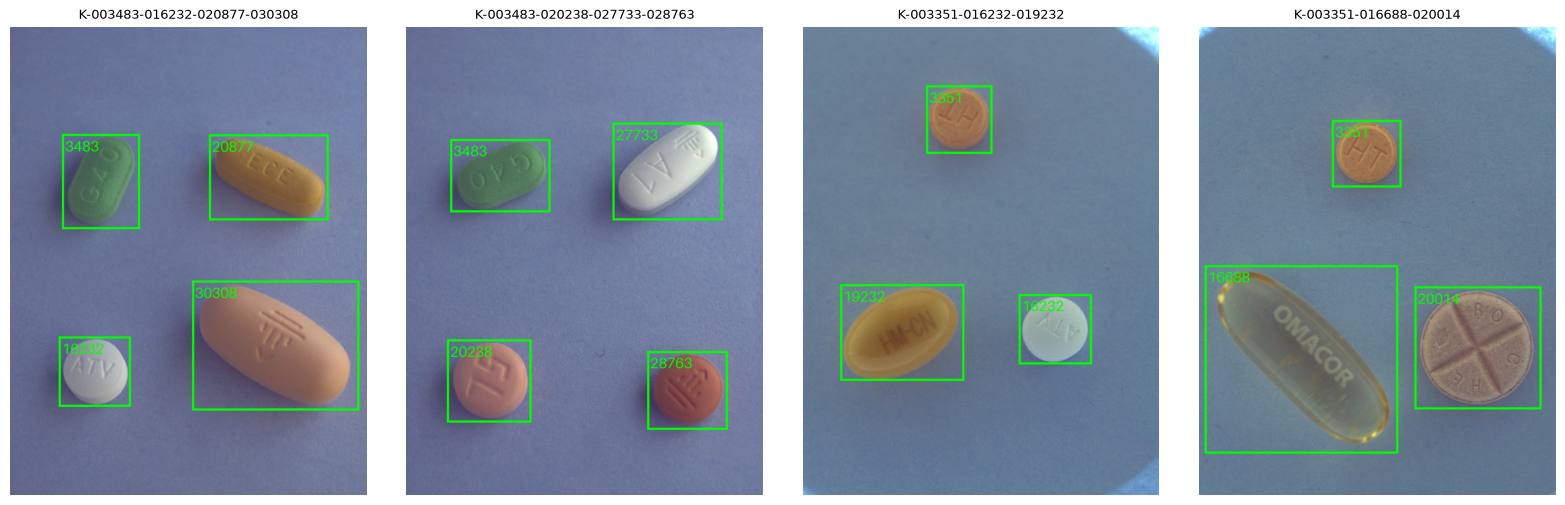

In [37]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

back = []
for split in ["train", "val"]:
    imgs = sorted((YOLO_DIR / "images" / split).glob("*.png"))
    txts = sorted((YOLO_DIR / "labels" / split).glob("*.txt"))
    n_broken = sum(not p.exists() for p in imgs)
    print(f"{split}: 사진 {len(imgs)}장, 라벨 {len(txts)}개, 깨진 링크 {n_broken}개")
    for txt in txts:
        for line in txt.read_text().splitlines():
            cls, cx, cy, w, h = line.split()
            back.append((f"{txt.stem}.png", int(cls), float(cx), float(cy), float(w), float(h)))

back = pd.DataFrame(back, columns=["file_name", "yolo_idx", "cx", "cy", "bw", "bh"])
back = back.join(size, on="file_name")
back["category_id"] = back["yolo_idx"].map(class_table.set_index("yolo_idx")["category_id"])
back["x"] = (back["cx"] - back["bw"] / 2) * back["width"]
back["y"] = (back["cy"] - back["bh"] / 2) * back["height"]
back["w"] = back["bw"] * back["width"]
back["h"] = back["bh"] * back["height"]
keys = ["file_name", "category_id"]
merged = labels.merge(back, on=keys, suffixes=("", "_back"))
max_err = max((merged[c] - merged[f"{c}_back"]).abs().max() for c in BOX)
print(f"박스 수: 라벨 표 {len(labels)}개, txt {len(back)}개, 짝지은 박스 {len(merged)}개")
print(f"픽셀 좌표 최대 오차: {max_err:.3f} (1 미만이어야 함)")

# val 사진 4장에 txt의 박스를 그린다
samples = back.loc[back["file_name"].map(split_of) == "val", "file_name"].drop_duplicates()
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, file_name in zip(axes, samples.sample(4, random_state=SEED), strict=True):
    img = Image.open(TRAIN_IMG_DIR / file_name).convert("RGB")
    draw = ImageDraw.Draw(img)
    for b in back[back["file_name"] == file_name].itertuples():
        draw.rectangle([b.x, b.y, b.x + b.w, b.y + b.h], outline="lime", width=6)
        draw.text((b.x + 8, b.y + 8), str(b.category_id), fill="lime", font_size=40)
    ax.imshow(img)
    ax.set_title(file_name.split("_")[0], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [38]:
# 데이터 준비 결과가 저장된 곳
show_outputs(DATA_OUT_DIR, max_files=5)

/content/pill-bbox/data/processed/yolo11m_kwon


,폴더,파일,크기
0,.,classes.csv,2.7 KB
1,.,labels.csv,99.9 KB
2,.,split_combo_s42.csv,17.2 KB
3,yolo_combo_fold0,data.yaml,0.9 KB
4,yolo_combo_fold0/images/train,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,1756.0 KB
5,yolo_combo_fold0/images/train,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,1635.2 KB
6,yolo_combo_fold0/images/train,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,1832.1 KB
7,yolo_combo_fold0/images/train,K-001900-016548-019607-033009_0_2_0_2_70_000_2...,1707.9 KB
8,yolo_combo_fold0/images/train,K-001900-016548-019607-033009_0_2_0_2_75_000_2...,1608.5 KB
9,yolo_combo_fold0/images/train,... 외 188개,


## 5. 학습

### 5-1. best.pt 기준을 mAP75-95로

ultralytics는 매 epoch 검증 뒤 fitness 값이 가장 높은 epoch를 `best.pt`로 저장하고, fitness가 `PATIENCE` epoch 동안 오르지 않으면 학습을 멈춥니다(early stopping). 기본 fitness는 mAP50-95라서, 검증 흐름은 그대로 두고 fitness만 대회 지표인 mAP75-95(IoU 0.75–0.95 다섯 단계 AP 평균)로 바꿉니다.

In [39]:
import time

from tqdm import tqdm
from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionTrainer
from ultralytics.utils import LOGGER

MAIN_KEY = "metrics/mAP75-95(B)"  # results.csv에 남는 열 이름


def map75_95(box) -> float:
    """검증 결과의 mAP75-95. all_ap는 클래스 × IoU 0.50–0.95(10단계) AP 표라 뒤 5열을 평균한다."""
    return float(box.all_ap[:, 5:].mean()) if len(box.all_ap) else 0.0


class Map7595Trainer(DetectionTrainer):
    """매 epoch 검증의 mAP75-95를 fitness로 쓴다. best.pt와 early stopping이 이 값을 따른다."""

    def validate(self) -> tuple[dict | None, float | None]:
        metrics = self.validator(self)
        if metrics is None:
            return None, None
        metrics.pop("fitness", None)  # 기본 fitness(mAP50-95)는 버린다
        fitness = map75_95(self.validator.metrics.box)
        metrics[MAIN_KEY] = round(fitness, 5)
        if self.best_fitness is None or fitness > self.best_fitness:
            self.best_fitness = fitness
        return metrics, fitness

### 5-2. epoch 진행 표시 (tqdm)

epoch가 끝날 때마다 tqdm 막대를 한 칸 올리고, 그 epoch에 걸린 시간(학습 + 검증)과 검증 지표를 한 줄로 출력합니다. ultralytics 자체 로그는 길어서 학습 중에는 경고만 보이게 줄입니다.

검증 코드가 기울기를 끊는지도 함께 기록합니다. ultralytics 검증 함수는 `torch.inference_mode()` 안에서 돌기 때문에 검증 중에는 `torch.is_grad_enabled()`가 False여야 하고, 학습 중에는 True여야 합니다.

In [40]:
VAL_KEYS = {
    "P": "metrics/precision(B)",
    "R": "metrics/recall(B)",
    "mAP50": "metrics/mAP50(B)",
    "mAP50-95": "metrics/mAP50-95(B)",
}


class EpochProgress:
    """ultralytics 콜백으로 epoch별 시간·검증 지표·기울기 상태를 모은다."""

    def __init__(self, epochs: int) -> None:
        self.bar = tqdm(total=epochs, desc="학습", unit="epoch")
        self.rows = []  # epoch별 기록
        self.final = None  # 학습이 끝난 뒤 best.pt로 한 검증
        self.epoch_start = None

    def on_train_epoch_start(self, trainer) -> None:
        self.epoch_start = time.time()
        self.grad = {}

    def on_train_batch_end(self, trainer) -> None:
        self.grad.setdefault("train", torch.is_grad_enabled())

    def on_val_start(self, validator) -> None:
        self.val_start = time.time()

    def on_val_batch_end(self, validator) -> None:
        # 검증 배치 안에서 기울기 계산이 꺼져 있는지 본다
        self.grad.setdefault("val", torch.is_grad_enabled())

    def on_val_end(self, validator) -> None:
        self.val_seconds = time.time() - self.val_start

    def on_fit_epoch_end(self, trainer) -> None:
        box = trainer.validator.metrics.box
        metrics = {name: trainer.metrics.get(key) for name, key in VAL_KEYS.items()}
        metrics["mAP75-95"] = map75_95(box)
        # 학습이 끝난 뒤 best.pt 검증에서도 이 콜백이 불린다. epoch 시작 기록이 없으면 그 경우다
        if self.epoch_start is None:
            self.final = metrics
            return
        row = {
            "epoch": trainer.epoch + 1,
            "시간(초)": time.time() - self.epoch_start,
            "검증(초)": self.val_seconds,
            **{k: float(v) for k, v in trainer.label_loss_items(trainer.tloss).items()},
            **metrics,
            "best epoch": trainer.stopper.best_epoch,
            "학습 중 기울기": self.grad.get("train"),
            "검증 중 기울기": self.grad.get("val"),
        }
        self.rows.append(row)
        self.epoch_start = None
        self.bar.update(1)
        self.bar.set_postfix({"mAP75-95": f"{row['mAP75-95']:.4f}", "best": row["best epoch"]})
        tqdm.write(
            f"epoch {row['epoch']:>2} | {row['시간(초)']:6.1f}초 (검증 {row['검증(초)']:.1f}초) | "
            f"P {row['P']:.3f} R {row['R']:.3f} mAP50 {row['mAP50']:.3f} "
            f"mAP75-95 {row['mAP75-95']:.4f} | best epoch {row['best epoch']} | "
            f"기울기 학습 {row['학습 중 기울기']} / 검증 {row['검증 중 기울기']}"
        )

    def callbacks(self) -> dict:
        """model.add_callback에 넘길 {이벤트 이름: 함수}."""
        events = [
            "on_train_epoch_start",
            "on_train_batch_end",
            "on_val_start",
            "on_val_batch_end",
            "on_val_end",
            "on_fit_epoch_end",
        ]
        return {event: getattr(self, event) for event in events}

### 5-3. 학습 실행

설정 셀의 값을 그대로 넘깁니다. `SMOKE = True`면 1 epoch, 학습 사진 10%로 동작만 확인합니다. 같은 실험 이름의 이전 결과는 지우고 새로 학습합니다(ultralytics가 results.csv를 이어 쓰기 때문).

- 전체 파인튜닝: `freeze`를 주지 않습니다.
- 증강: 노션에 정한 값이 없어 ultralytics 기본값을 씁니다.
- 학습 중 검증도 평가와 같은 `conf`, NMS `iou`, `max_det`로 합니다.

In [41]:
train_args = {
    "data": str(DATA_YAML),
    "epochs": 1 if SMOKE else EPOCHS,
    "fraction": 0.1 if SMOKE else 1.0,
    "patience": PATIENCE,
    "batch": BATCH,
    "imgsz": IMGSZ,
    "optimizer": OPTIMIZER,
    "lr0": LR0,
    "seed": SEED,
    "deterministic": True,
    "device": DEVICE,
    "conf": EVAL_CONF,
    "iou": NMS_IOU,
    "max_det": MAX_DET,
    "project": str(RUNS_OUT_DIR),
    "name": EXP,
    "exist_ok": True,  # 폴더 이름을 EXP로 고정한다 (뒤에 2, 3이 붙지 않게)
}
if EXP_DIR.exists():
    shutil.rmtree(EXP_DIR)

set_seed(SEED)
progress = EpochProgress(train_args["epochs"])
model = YOLO(MODEL)
for event, func in progress.callbacks().items():
    model.add_callback(event, func)

log_level = LOGGER.level
LOGGER.setLevel("WARNING")  # ultralytics 배치별 진행 막대와 정보 로그를 끈다
start = time.time()
try:
    model.train(trainer=Map7595Trainer, **train_args)
finally:
    LOGGER.setLevel(log_level)
    progress.bar.close()
print(f"전체 {(time.time() - start) / 60:.1f}분")

학습:   3%|▎         | 1/30 [00:24<11:51, 24.53s/epoch, mAP75-95=0.0095, best=1]  

epoch  1 |   21.4초 (검증 2.2초) | P 0.283 R 0.014 mAP50 0.016 mAP75-95 0.0095 | best epoch 1 | 기울기 학습 True / 검증 False


학습:   7%|▋         | 2/30 [00:32<07:00, 15.00s/epoch, mAP75-95=0.0621, best=2]  

epoch  2 |    8.3초 (검증 0.5초) | P 0.152 R 0.124 mAP50 0.082 mAP75-95 0.0621 | best epoch 2 | 기울기 학습 True / 검증 False


학습:  10%|█         | 3/30 [00:41<05:22, 11.93s/epoch, mAP75-95=0.1316, best=3]  

...

epoch 29 |    7.5초 (검증 0.4초) | P 0.976 R 0.959 mAP50 0.994 mAP75-95 0.9545 | best epoch 25 | 기울기 학습 True / 검증 False


학습: 100%|██████████| 30/30 [05:18<00:00,  8.24s/epoch, mAP75-95=0.9552, best=25]  

epoch 30 |    7.2초 (검증 0.4초) | P 0.976 R 0.961 mAP50 0.994 mAP75-95 0.9552 | best epoch 25 | 기울기 학습 True / 검증 False


학습: 100%|██████████| 30/30 [05:31<00:00, 11.06s/epoch, mAP75-95=0.9552, best=25]

전체 5.5분


### 5-4. 학습 결과

epoch별 기록과 best.pt 정보, 결과 파일이 저장된 곳입니다. Colab에서는 런타임이 끝나면 이 파일들이 사라지고, 노트북 출력만 남습니다.

In [42]:
history = pd.DataFrame(progress.rows)
best = history.loc[history["mAP75-95"].idxmax()]
stopped = " (early stopping)" if len(history) < train_args["epochs"] else ""
print(f"학습한 epoch: {len(history)} / {train_args['epochs']}{stopped}")
print(f"epoch당 평균 {history['시간(초)'].mean():.1f}초")
print(f"best epoch {int(best['epoch'])}: mAP75-95 {best['mAP75-95']:.4f}")
if progress.final is not None:
    print("best.pt 최종 검증: " + ", ".join(f"{k} {v:.4f}" for k, v in progress.final.items()))
print(f"best.pt: {WEIGHTS_DIR / 'best.pt'} (있음: {(WEIGHTS_DIR / 'best.pt').exists()})")
history.round(4)

학습한 epoch: 30 / 30
epoch당 평균 10.5초
best epoch 25: mAP75-95 0.9667
best.pt 최종 검증: P 0.9701, R 0.9546, mAP50 0.9942, mAP50-95 0.9794, mAP75-95 0.9647
best.pt: /content/pill-bbox/runs/yolo11m_kwon/yolo11m_MuSGD_lr0.001_combo_fold0/weights/best.pt (있음: True)


,epoch,시간(초),검증(초),train/box_loss,train/cls_loss,train/dfl_loss,P,R,mAP50,mAP50-95,mAP75-95,best epoch,학습 중 기울기,검증 중 기울기
0,1,21.4399,2.1655,1.3044,4.8165,1.3189,0.2834,0.0136,0.0158,0.0126,0.0095,1,True,False
1,2,8.3257,0.4747,0.9926,3.9634,1.1807,0.1523,0.1238,0.0816,0.0719,0.0621,2,True,False
2,3,8.2630,0.4384,0.6430,3.0330,0.9900,0.1845,0.1708,0.1445,0.1380,0.1316,3,True,False
3,4,7.7969,0.5093,0.5707,2.4420,0.9481,0.2633,0.2285,0.1837,0.1735,0.1633,4,True,False
4,5,8.6265,0.4891,0.4645,1.9213,0.9179,0.2857,0.2811,0.2292,0.2132,0.1972,5,True,False
5,6,7.9272,0.4405,0.4910,1.6810,0.9515,0.3981,0.3877,0.3103,0.2963,0.2823,6,True,False
6,7,7.8625,0.4794,0.4687,1.4793,0.9298,0.5087,0.5150,0.4576,0.4328,0.4079,7,True,False
7,8,11.7843,0.5260,0.4353,1.2047,0.9033,0.8551,0.8520,0.8247,0.7894,0.7541,8,True,False
8,9,7.6435,0.5038,0.4037,1.0381,0.8972,0.7680,0.8168,0.7984,0.7705,0.7427,8,True,False
9,10,12.8100,0.4754,0.4100,0.9448,0.9220,0.7574,0.8460,0.8303,0.8041,0.7779,10,True,False


### 5-5. 학습 곡선

ultralytics가 epoch마다 쓰는 `results.csv`로 그립니다. 회색 점선은 best epoch(검증 mAP75-95 최고)입니다.

- 윗줄: loss 세 가지(박스 위치 `box`, 클래스 `cls`, 박스 경계 분포 `dfl`). 실선이 train, 점선이 val입니다. train은 내려가는데 val이 올라가면 과적합입니다. train loss는 증강한 사진으로 잰 값이라 val보다 높게 나올 수 있습니다.
- 윗줄 오른쪽: epoch당 걸린 시간과 학습률. 학습률은 파라미터 묶음마다 한 줄입니다. MuSGD는 분류 head에 학습률 3배(0.003)를 주므로 선이 0.001과 0.003 두 높이로 나뉘고, 처음 몇 epoch는 warmup으로 값이 바뀝니다.
- 아랫줄: 검증 지표 Precision, Recall, mAP50, mAP50-95, mAP75-95. 빨간 별은 best.pt를 고른 지점입니다.

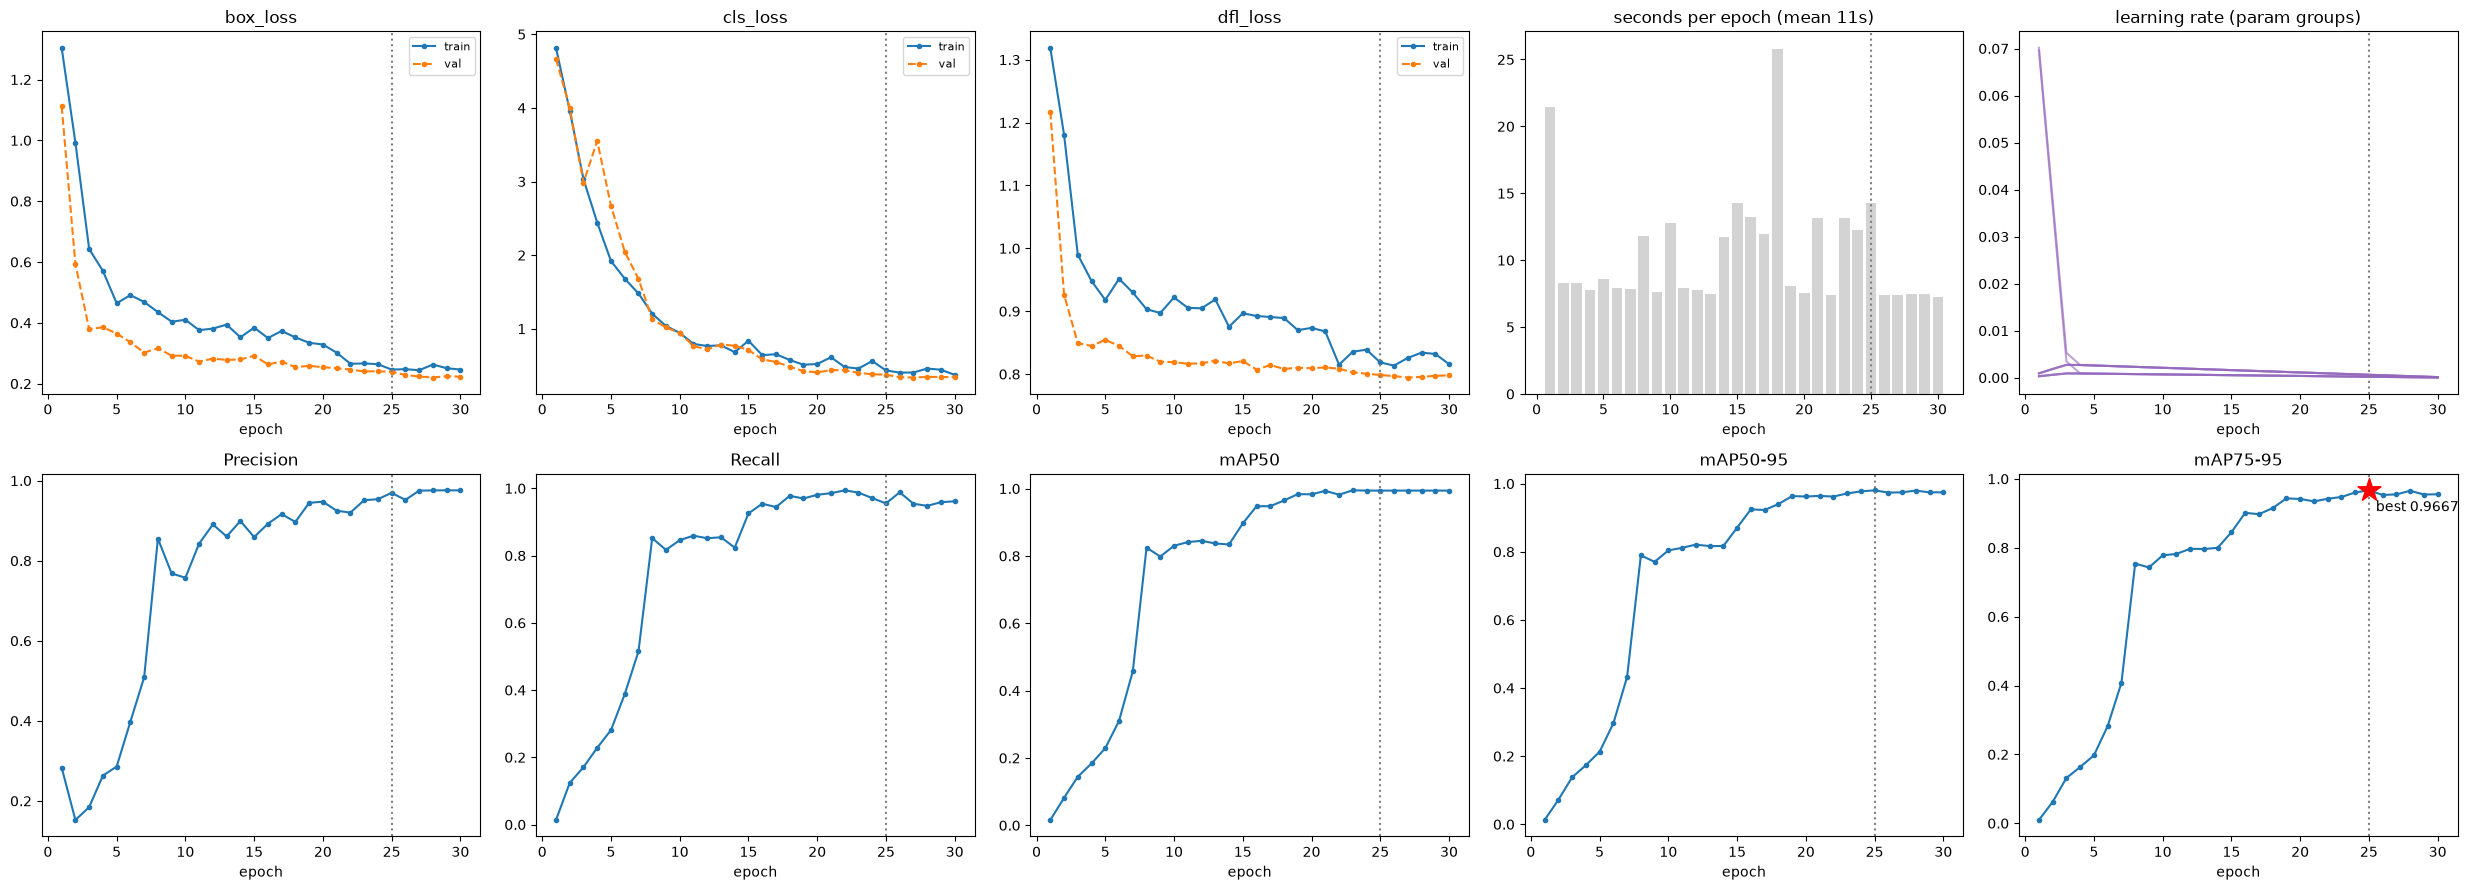

In [43]:
curves = pd.read_csv(EXP_DIR / "results.csv")
curves.columns = curves.columns.str.strip()
best_epoch = int(best["epoch"])
epoch = curves["epoch"]
loss_names = ["box_loss", "cls_loss", "dfl_loss"]
metric_keys = {
    "Precision": "metrics/precision(B)",
    "Recall": "metrics/recall(B)",
    "mAP50": "metrics/mAP50(B)",
    "mAP50-95": "metrics/mAP50-95(B)",
    "mAP75-95": MAIN_KEY,
}

fig, axes = plt.subplots(2, 5, figsize=(25, 9))
for ax, name in zip(axes[0], loss_names, strict=False):
    ax.plot(epoch, curves[f"train/{name}"], marker=".", label="train")
    ax.plot(epoch, curves[f"val/{name}"], marker=".", linestyle="--", label="val")
    ax.set_title(name)

ax = axes[0, 3]
ax.bar(history["epoch"], history["시간(초)"], color="lightgray")
ax.set_title(f"seconds per epoch (mean {history['시간(초)'].mean():.0f}s)")

ax = axes[0, 4]
# 파라미터 묶음(lr/pg0, pg1, ...)마다 한 줄. 범례 없이 높이만 본다
for col in [c for c in curves.columns if c.startswith("lr/")]:
    ax.plot(epoch, curves[col], color="tab:purple", alpha=0.6)
ax.set_title("learning rate (param groups)")

for ax, (title, key) in zip(axes[1], metric_keys.items(), strict=True):
    ax.plot(epoch, curves[key], marker=".")
    ax.set_title(title)
best_score = curves.loc[epoch == best_epoch, MAIN_KEY].iloc[0]
axes[1, 4].scatter(best_epoch, best_score, marker="*", s=300, color="red", zorder=3)
axes[1, 4].annotate(
    f"best {best_score:.4f}", (best_epoch, best_score), xytext=(5, -15), textcoords="offset points"
)

for ax in axes.flat:
    ax.axvline(best_epoch, color="gray", linestyle=":")
    ax.set_xlabel("epoch")
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [44]:
# 학습 결과가 저장된 곳
show_outputs(EXP_DIR, max_files=20)

/content/pill-bbox/runs/yolo11m_kwon/yolo11m_MuSGD_lr0.001_combo_fold0


,폴더,파일,크기
0,.,BoxF1_curve.png,218.4 KB
1,.,BoxPR_curve.png,68.5 KB
2,.,BoxP_curve.png,125.2 KB
3,.,BoxR_curve.png,208.0 KB
4,.,args.yaml,1.8 KB
5,.,confusion_matrix.png,310.3 KB
6,.,confusion_matrix_normalized.png,313.6 KB
7,.,labels.jpg,121.9 KB
8,.,results.csv,5.2 KB
9,.,results.png,286.8 KB


## 6. 평가

학습이 끝난 `best.pt`로 val을 다시 평가합니다. 평가 설정은 conf 0.001, NMS IoU 0.5, 최대 탐지 4입니다.

- **mAP75-95**: 주 지표. IoU 0.75–0.95(0.05 간격 5단계) AP의 평균이며 대회 채점 지표와 같습니다.
- **Precision / Recall**: ultralytics 방식으로, 신뢰도 하한을 바꿔 가며 F1(정밀도·재현율의 조화 평균)이 가장 높아지는 지점의 값입니다. conf 0.001에서의 값이 아닙니다.
- **추론속도**: 사진 한 장당 ms. 전처리·추론·후처리(NMS)를 따로 보여 주고 **합계를 대표값**으로 씁니다. `BATCH`장씩 묶어 처리한 시간을 사진 수로 나눈 값이라, 모델끼리는 같은 GPU·같은 배치에서 잰 값끼리만 비교합니다.

In [45]:
from IPython.display import display

best_pt = WEIGHTS_DIR / "best.pt"
if not best_pt.is_file():
    raise FileNotFoundError(f"{best_pt}가 없습니다. 5. 학습을 먼저 실행하세요.")

val_result = YOLO(best_pt).val(
    data=str(DATA_YAML),
    imgsz=IMGSZ,
    batch=BATCH,
    conf=EVAL_CONF,
    iou=NMS_IOU,
    max_det=MAX_DET,
    device=DEVICE,
    plots=False,
    verbose=False,
    project=str(EXP_DIR),
    name="eval",
    exist_ok=True,
)
box = val_result.box
speed = val_result.speed  # 사진 한 장당 ms. loss는 학습 중 검증에서만 재므로 뺀다
speed_ms = {
    "전처리": speed["preprocess"],
    "추론": speed["inference"],
    "후처리(NMS)": speed["postprocess"],
}
total_ms = sum(speed_ms.values())
gpu = torch.cuda.get_device_name(0) if DEVICE == "cuda" else DEVICE

scores = pd.DataFrame(
    [
        {
            "mAP75-95": map75_95(box),
            "mAP50": box.map50,
            "mAP50-95": box.map,
            "Precision": box.mp,
            "Recall": box.mr,
            "추론속도(ms/사진)": total_ms,
        }
    ],
    index=[EXP],
)
speed_table = pd.DataFrame({"ms/사진": {**speed_ms, "합계": total_ms}})

print(f"best.pt: {best_pt}")
print(f"val 사진 {(images['fold'] == FOLD).sum()}장")
print(f"속도 측정: {gpu}, batch {BATCH}, imgsz {IMGSZ}")
display(scores.round(4))
display(speed_table.round(2))

Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.14.1+cu126 CUDA:0 (Tesla T4, 14913MiB)


YOLO11m summary (fused): 125 layers, 20,073,208 parameters, 0 gradients, 68.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4811.7±1426.2 MB/s, size: 1673.8 KB)
val: Scanning /content/pill-bbox/data/processed/yolo11m_kwon/yolo_combo_fold0/labels/val.cache... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 9.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.5it/s 2.0s1.1s
                   all         39        123      0.969      0.955      0.994      0.979
Speed: 1.7ms preprocess, 20.3ms inference, 0.0ms loss, 2.6ms postprocess per image
best.pt: /content/pill-bbox/runs/yolo11m_kwon/yolo11m_MuSGD_lr0.001_combo_fold0/weights/best.pt
val 사진 39장
속도 측정: Tesla T4, batch 16, imgsz 640


,mAP75-95,mAP50,mAP50-95,Precision,Recall,추론속도(ms/사진)
yolo11m_MuSGD_lr0.001_combo_fold0,0.9648,0.9942,0.9795,0.9692,0.9554,24.6581


,ms/사진
전처리,1.71
추론,20.32
후처리(NMS),2.63
합계,24.66


### 6-2. 과적합 점검

과적합은 모델이 train 사진을 외워서 처음 보는 사진(val)에서 성능이 떨어지는 상태입니다. 두 가지 근거를 숫자로 봅니다.

1. **학습 곡선 추세**: val loss가 가장 낮았던 epoch 뒤로 다시 오르는데 train loss는 계속 내려가는지, val mAP75-95가 best 뒤로 떨어지는지 봅니다.
2. **train과 val 성능 차이**: best.pt로 train 사진도 val과 같은 조건(증강 없음, conf 0.001, NMS IoU 0.5, 최대 4개)으로 평가해 비교합니다. train이 val보다 훨씬 높으면 외운 것입니다.

5-5 그림에서 train loss가 val loss보다 높은 것은 과적합과 관계없습니다. train loss는 mosaic 등으로 증강한 사진에서 잰 값이라 val loss와 바로 비교할 수 없습니다. 그래서 2번처럼 같은 조건으로 다시 잽니다.

그림 오른쪽은 val loss를 각자의 최저값으로 나눈 값입니다. 초반에는 위에서 내려오는 것이 정상이고, **최저점(1)을 찍은 뒤 다시 올라 빨간 점선을 넘으면** 과적합 신호입니다.

`OVERFIT_*` 기준값은 판단을 돕는 경험치입니다. val이 39장이라 사진 1–2장에도 값이 흔들리므로, 신호가 나오면 5-5 곡선과 함께 봅니다. `SMOKE`(1 epoch)에서는 곡선 추세 점검이 의미가 없습니다.

In [ ]:
# 과적합 신호로 볼 기준 (경험치)
OVERFIT_LOSS_RISE = 0.10  # val loss가 최저점보다 10% 넘게 다시 올랐는가
OVERFIT_MAP_DROP = 0.02  # 마지막 epoch의 val mAP75-95가 best보다 0.02 넘게 낮은가
OVERFIT_GAP = 0.05  # train mAP75-95가 val보다 0.05 넘게 높은가

# 1) 학습 곡선 추세 (5-5의 results.csv)
checks = []
for name in loss_names:
    val_loss, train_loss = curves[f"val/{name}"], curves[f"train/{name}"]
    i_min = int(val_loss.to_numpy().argmin())  # 행 번호가 아니라 순서 위치
    rise = val_loss.iloc[-1] / val_loss.iloc[i_min] - 1
    train_falling = bool(train_loss.iloc[-1] < train_loss.iloc[i_min])
    checks.append(
        {
            "점검": f"val {name}: 최저점 뒤 상승",
            "값": f"최저 epoch {int(curves['epoch'].iloc[i_min])}, 마지막까지 {rise:+.1%}"
            + (", train은 하락" if train_falling else ", train도 하락 안 함"),
            "기준": f"+{OVERFIT_LOSS_RISE:.0%} 초과 & train 하락",
            "과적합 신호": rise > OVERFIT_LOSS_RISE and train_falling,
        }
    )
val_map = curves[MAIN_KEY]
best_at = int(val_map.to_numpy().argmax())
map_drop = val_map.max() - val_map.iloc[-1]
checks.append(
    {
        "점검": "val mAP75-95: best 뒤 하락",
        "값": f"best {val_map.max():.4f} (epoch {int(curves['epoch'].iloc[best_at])})"
        f" → 마지막 {val_map.iloc[-1]:.4f}",
        "기준": f"{OVERFIT_MAP_DROP} 초과 하락",
        "과적합 신호": bool(map_drop > OVERFIT_MAP_DROP),
    }
)

# 2) train과 val 성능 차이: train 사진을 val과 같은 조건으로 평가한다
train_result = YOLO(best_pt).val(
    data=str(DATA_YAML),
    split="train",
    imgsz=IMGSZ,
    batch=BATCH,
    conf=EVAL_CONF,
    iou=NMS_IOU,
    max_det=MAX_DET,
    device=DEVICE,
    plots=False,
    verbose=False,
    project=str(EXP_DIR),
    name="eval_train",
    exist_ok=True,
)


def scores_of(b) -> dict:
    """검증 결과(box)의 주요 지표."""
    return {
        "mAP75-95": map75_95(b),
        "mAP50": b.map50,
        "mAP50-95": b.map,
        "Precision": b.mp,
        "Recall": b.mr,
    }


gap_table = pd.DataFrame({"train": scores_of(train_result.box), "val": scores_of(val_result.box)})
gap_table["차이 (train - val)"] = gap_table["train"] - gap_table["val"]
gap = gap_table.loc["mAP75-95", "차이 (train - val)"]
checks.append(
    {
        "점검": "train과 val의 mAP75-95 차이",
        "값": f"train {gap_table.loc['mAP75-95', 'train']:.4f} / val "
        f"{gap_table.loc['mAP75-95', 'val']:.4f} ({gap:+.4f})",
        "기준": f"{OVERFIT_GAP} 초과",
        "과적합 신호": bool(gap > OVERFIT_GAP),
    }
)

check_table = pd.DataFrame(checks)
n_signals = int(check_table["과적합 신호"].sum())
if len(curves) < 5:
    print(f"epoch가 {len(curves)}개뿐이라 곡선 추세 점검은 의미가 없습니다 (SMOKE).")
if n_signals:
    print(f"과적합 신호 {n_signals}개: 해당 항목과 5-5 학습 곡선을 함께 확인하세요.")
else:
    print("과적합 신호 없음: val loss가 다시 오르지 않았고 train과 val 성능 차이도 기준 안입니다.")
display(check_table)
display(gap_table.round(4))

In [ ]:
# 왼쪽: 같은 조건으로 잰 train과 val 지표. 오른쪽: val loss를 각자의 최저값으로 나눈 값
# (1보다 위로 올라가면 최저점 뒤 다시 오른 것, 점선이 과적합 기준)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
x = np.arange(len(gap_table))
ax.bar(x - 0.2, gap_table["train"], width=0.4, label="train (no aug)")
ax.bar(x + 0.2, gap_table["val"], width=0.4, label="val")
ax.set_xticks(x, gap_table.index)
ax.set_ylim(0, 1.2)  # 위쪽에 범례 자리를 둔다
ax.set_title("train vs val (best.pt, same eval settings)")
ax.legend(loc="upper center", ncol=2)

ax = axes[1]
last_rel = []
for name in loss_names:
    rel = curves[f"val/{name}"] / curves[f"val/{name}"].min()
    ax.plot(curves["epoch"], rel, marker=".", label=f"val {name}")
    last_rel.append(rel.iloc[-1])
ax.axhline(1 + OVERFIT_LOSS_RISE, color="red", linestyle="--", label="overfit threshold")
ax.axhline(1, color="gray", linestyle=":")
# 초반 epoch의 큰 값은 잘라 내고 최저점(1) 근처를 크게 본다
ax.set_ylim(0.9, max(1.5, max(last_rel) + 0.1))
ax.set_xlabel("epoch")
ax.set_title("val loss / its minimum")
ax.legend()
plt.tight_layout()
plt.show()

# 약별로 train과 val의 AP75-95 차이가 큰 순. 두 쪽에 모두 있는 약만
per_class = pd.DataFrame(
    {
        "train AP75-95": pd.Series(
            train_result.box.all_ap[:, 5:].mean(1), index=train_result.box.ap_class_index
        ),
        "val AP75-95": pd.Series(
            val_result.box.all_ap[:, 5:].mean(1), index=val_result.box.ap_class_index
        ),
    }
).dropna()
per_class["차이"] = per_class["train AP75-95"] - per_class["val AP75-95"]
per_class = per_class.join(class_table.set_index("yolo_idx")[["category_id", "dl_name"]])
per_class.sort_values("차이", ascending=False).head(10).round(3)

## 7. 혼동행렬 (conf 0.25 고정)

혼동행렬은 `CM_CONF = 0.25`로 고정합니다. mAP 평가(6단계)는 그대로 conf 0.001입니다.

### 0.25로 고정한 이유

처음에는 conf 0.001과 0.25 두 가지로 혼동행렬을 만들어 비교했습니다. 아래 숫자와 그림은 2026-10-30 fold 0 본 학습(30 epoch, best epoch 25) 결과입니다.

| conf | 정답 박스 | 맞힘 | 헷갈림 | 놓침 | 오검출 | 값이 있는 칸 |
|---|---|---|---|---|---|---|
| 0.001 | 123 | 99 | 24 | 0 | 33 | 55 |
| 0.25 | 123 | 117 | 6 | 0 | 5 | 31 |

1. **0.001은 칸이 많아 읽기 어렵다.** 값이 있는 칸이 55개로 0.25(31개)보다 많고, 늘어난 칸은 대부분 신뢰도가 낮은 박스다. 사진당 최대 4개까지 자신 없는 박스도 모두 남기 때문이다.
2. **0.001에서는 숫자가 실제 오류를 잘못 보여 준다.** conf를 낮춰 박스를 더 남겼는데 맞힘이 117에서 99로 줄었다. 0.25에서 맞힌 박스는 0.001에서도 그대로 있으므로 모델이 더 틀린 것이 아니다. ultralytics 혼동행렬은 정답과 예측을 짝지을 때 conf는 보지 않고 IoU만 본다. 그래서 한 알약 위에 conf 0.9인 정답 약 박스와 conf 0.01인 다른 약 박스가 겹쳐 있으면, IoU가 조금 더 큰 0.01짜리가 짝이 되어 **헷갈림**으로 세고, 짝을 잃은 0.9짜리는 **오검출**로 센다. 이런 짝 바뀜이 18번이면 맞힘 117 − 18 = 99, 헷갈림 6 + 18 = 24로 표의 숫자와 맞는다.
3. **mAP와 혼동행렬은 conf를 쓰는 방식이 다르다.** mAP는 박스를 conf 순으로 줄 세워 계산하므로 낮은 박스를 남겨도 점수가 깎이지 않아 0.001이 맞다. 혼동행렬은 줄 세우지 않고 남은 박스를 모두 모델의 답으로 치므로, 실제로 판정에 쓸 만한 신뢰도(0.25)에서 봐야 모델의 실수를 그대로 보여 준다.

비교했던 그림 (왼쪽 conf 0.001, 오른쪽 conf 0.25. 행은 예측, 열은 정답, `bg`는 배경):

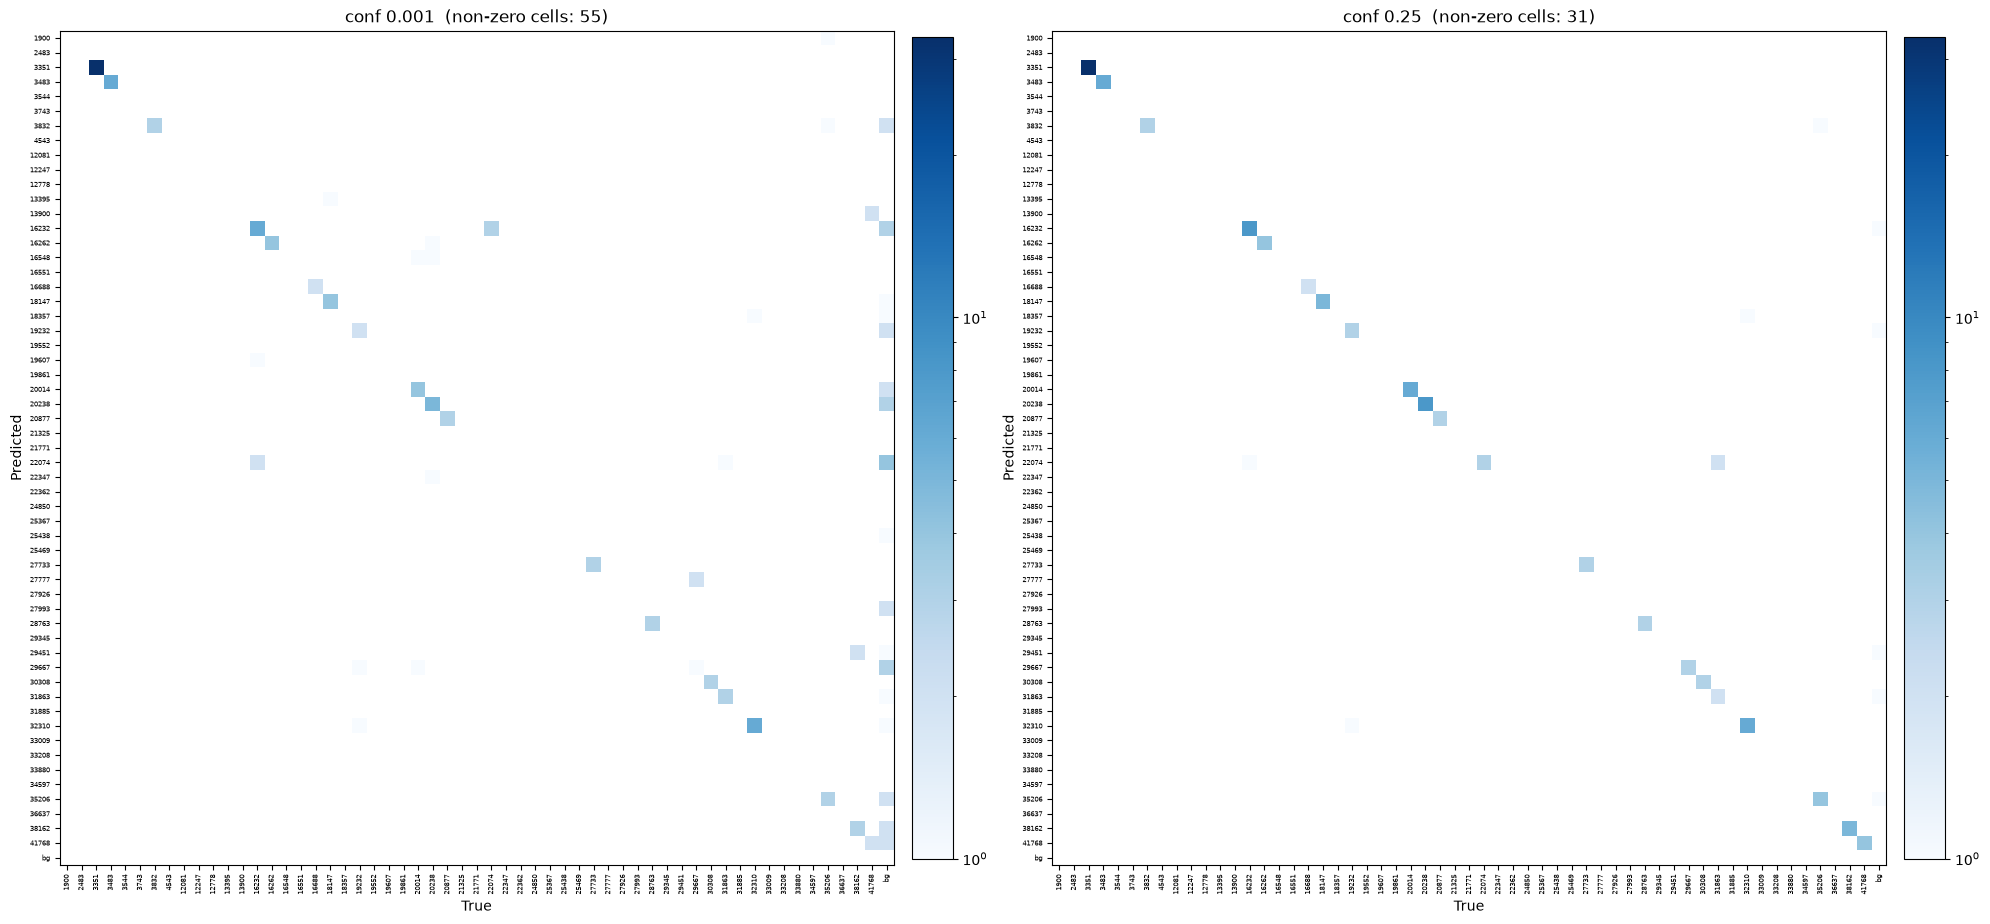

### 혼동행렬 읽는 법

행은 예측, 열은 정답이고 마지막 행·열은 배경입니다. 예측과 정답 박스는 IoU 0.45 이상일 때 짝지어집니다(ultralytics 기준).

- **맞힘**: 정답과 같은 약으로 예측 (대각선)
- **헷갈림**: 박스 위치는 맞았지만 다른 약으로 예측
- **놓침**: 정답 박스에 짝지어진 예측이 없음 (맨 아래 배경 행)
- **오검출**: 정답이 없는 곳에 예측 (맨 오른쪽 배경 열)

In [ ]:
best_model = YOLO(best_pt)
n_classes = len(class_table)
cm_result = best_model.val(
    data=str(DATA_YAML),
    imgsz=IMGSZ,
    batch=BATCH,
    conf=CM_CONF,
    iou=NMS_IOU,
    max_det=MAX_DET,
    device=DEVICE,
    plots=True,  # 혼동행렬은 plots=True일 때만 계산된다
    verbose=False,
    project=str(EXP_DIR),
    name=f"confusion_conf{CM_CONF:g}",
    exist_ok=True,
)
cm = cm_result.confusion_matrix.matrix.copy()  # [예측, 정답], 마지막 행·열은 배경
cls = cm[:n_classes, :n_classes]
pd.DataFrame(
    [
        {
            "정답 박스": int(cm[:, :n_classes].sum()),
            "맞힘": int(np.trace(cls)),
            "헷갈림": int(cls.sum() - np.trace(cls)),
            "놓침": int(cm[n_classes, :n_classes].sum()),
            "오검출": int(cm[:n_classes, n_classes].sum()),
            "값이 있는 칸": int((cm > 0).sum()),
        }
    ],
    index=pd.Index([CM_CONF], name="conf"),
)

In [ ]:
from matplotlib.colors import LogNorm

# 0인 칸은 흰색으로 두고 값이 있는 칸만 색칠한다. 1–2개인 칸도 보이도록 색은 로그 눈금
# 축 눈금은 원본 약 번호(category_id), bg는 배경
tick_labels = [*class_table["category_id"].astype(str), "bg"]
fig, ax = plt.subplots(figsize=(11, 10))
norm = LogNorm(vmin=1, vmax=max(cm.max(), 2))
image = ax.imshow(np.ma.masked_equal(cm, 0), cmap="Blues", norm=norm)
ax.set_title(f"conf {CM_CONF:g}  (non-zero cells: {int((cm > 0).sum())})")
ax.set_xlabel("True")
ax.set_ylabel("Predicted")
ax.set_xticks(range(len(tick_labels)), tick_labels, rotation=90, fontsize=5)
ax.set_yticks(range(len(tick_labels)), tick_labels, fontsize=5)
ax.grid(False)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.02)
plt.tight_layout()
plt.show()

In [ ]:
# 다른 약으로 헷갈린 쌍. 개수가 많은 순
names = class_table.set_index("yolo_idx")[["category_id", "dl_name"]]
off = cls.copy()
np.fill_diagonal(off, 0)
pred_idx, true_idx = np.nonzero(off)
pd.DataFrame(
    {
        "정답 약": names.loc[true_idx, "category_id"].to_numpy(),
        "정답 이름": names.loc[true_idx, "dl_name"].to_numpy(),
        "예측 약": names.loc[pred_idx, "category_id"].to_numpy(),
        "예측 이름": names.loc[pred_idx, "dl_name"].to_numpy(),
        "개수": off[pred_idx, true_idx].astype(int),
    }
).sort_values("개수", ascending=False, ignore_index=True)

## 8. 실패 사례 시각화

학습에 쓰지 않은 val 사진을 `best.pt`로 예측하고, 정답 박스와 예측 박스를 함께 그립니다. 그림에는 신뢰도 `PLOT_CONF`(0.25) 이상인 예측만 그립니다.

예측 박스는 신뢰도가 높은 것부터 아직 짝이 없는 정답 박스 중 가장 많이 겹치는 것과 짝짓고, 아래처럼 나눕니다.

| 종류 | 뜻 | 그림 색 (그림 속 글자) |
|---|---|---|
| 정답 | IoU 0.75 이상, 약도 맞음 | 초록 (ok) |
| 위치 부정확 | 약은 맞지만 IoU 0.5–0.75. 주 지표 mAP75-95에서는 틀린 것과 같다 | 주황 (loose) |
| 다른 약 | 위치는 맞지만(IoU 0.5 이상) 다른 약으로 예측 | 빨강 (wrong) |
| 오검출 | 어떤 정답과도 IoU 0.5 미만 | 보라 (FP) |
| 놓침 | 짝지어진 예측이 없는 정답 박스 | 노랑 굵은 선 (miss) |

정답 박스는 모두 흰 선으로 먼저 그리고, 그 위에 예측 박스를 종류별 색으로 그립니다.

In [49]:
MATCH_IOU = 0.5  # 이 이상 겹치면 같은 알약을 가리킨 것으로 본다
GOOD_IOU = 0.75  # 주 지표 mAP75-95의 가장 낮은 IoU 기준
KINDS = ["정답", "위치 부정확", "다른 약", "오검출", "놓침"]


def box_iou(box: np.ndarray, boxes: np.ndarray) -> np.ndarray:
    """xyxy 박스 하나와 여러 xyxy 박스의 IoU."""
    w = np.clip(np.minimum(box[2], boxes[:, 2]) - np.maximum(box[0], boxes[:, 0]), 0, None)
    h = np.clip(np.minimum(box[3], boxes[:, 3]) - np.maximum(box[1], boxes[:, 1]), 0, None)
    inter = w * h
    area = (box[2] - box[0]) * (box[3] - box[1])
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return inter / (area + areas - inter)


to_cid = class_table.set_index("yolo_idx")["category_id"]
val_files = images.loc[images["fold"] == FOLD, "file_name"].tolist()
records = []
for result in best_model.predict(
    source=[str(TRAIN_IMG_DIR / f) for f in val_files],
    imgsz=IMGSZ,
    conf=PLOT_CONF,
    iou=NMS_IOU,
    max_det=MAX_DET,
    device=DEVICE,
    stream=True,
    verbose=False,
):
    file_name = Path(result.path).name
    gt = labels[labels["file_name"] == file_name]
    gt_boxes = np.c_[gt["x"], gt["y"], gt["x"] + gt["w"], gt["y"] + gt["h"]].astype(float)
    gt_cids = gt["category_id"].to_numpy()
    matched = np.zeros(len(gt), dtype=bool)
    preds = result.boxes
    for i in preds.conf.argsort(descending=True).tolist():
        box = preds.xyxy[i].cpu().numpy()
        pred_cid = int(to_cid[int(preds.cls[i])])
        ious = np.where(matched, 0.0, box_iou(box, gt_boxes))
        j = int(ious.argmax())
        row = {"file_name": file_name, "pred_cid": pred_cid, "conf": float(preds.conf[i])}
        row |= {"pred_box": box, "iou": float(ious[j])}
        if ious[j] >= MATCH_IOU:
            matched[j] = True
            if pred_cid != gt_cids[j]:
                kind = "다른 약"
            else:
                kind = "위치 부정확" if ious[j] < GOOD_IOU else "정답"
            row |= {"kind": kind, "gt_cid": int(gt_cids[j]), "gt_box": gt_boxes[j]}
        else:
            row |= {"kind": "오검출", "gt_cid": None, "gt_box": None}
        records.append(row)
    for j in np.flatnonzero(~matched):
        records.append(
            {
                "file_name": file_name,
                "kind": "놓침",
                "gt_cid": int(gt_cids[j]),
                "gt_box": gt_boxes[j],
                "pred_cid": None,
                "pred_box": None,
                "iou": np.nan,
                "conf": np.nan,
            }
        )
cases = pd.DataFrame(records)
# 빈 값(None)이 섞여 실수(3351.0)가 되지 않게 정수형으로 둔다
cases[["gt_cid", "pred_cid"]] = cases[["gt_cid", "pred_cid"]].astype("Int64")

# 사진별로 종류마다 몇 개인지 센다
per_image = (
    cases.pivot_table(index="file_name", columns="kind", values="conf", aggfunc="size")
    .reindex(index=val_files, columns=KINDS)
    .fillna(0)
    .astype(int)
)
n_gt = len(labels[labels["file_name"].isin(val_files)])
print(f"val 사진 {len(val_files)}장, 정답 박스 {n_gt}개, 그림용 conf {PLOT_CONF}")
print(f"알약을 놓친 사진: {(per_image['놓침'] > 0).sum()}장")
print(f"잘못 예측한 박스가 있는 사진: {(per_image[KINDS[1:4]].sum(axis=1) > 0).sum()}장")
per_image.sum().to_frame("박스 수").T

val 사진 39장, 정답 박스 123개, 그림용 conf 0.25
알약을 놓친 사진: 0장
잘못 예측한 박스가 있는 사진: 6장


kind,정답,위치 부정확,다른 약,오검출,놓침
박스 수,120,0,3,4,0


In [50]:
COLORS = {
    "정답": "lime",
    "위치 부정확": "orange",
    "다른 약": "red",
    "오검출": "magenta",
    "놓침": "yellow",
}
SHORT = {"정답": "ok", "위치 부정확": "loose", "다른 약": "wrong", "오검출": "FP", "놓침": "miss"}
N_SHOW = 8  # 종류마다 보여 줄 사진 수


def draw_case(ax: plt.Axes, file_name: str) -> None:
    """사진 한 장에 정답 박스(흰색)와 예측 박스(종류별 색)를 그린다."""
    img = Image.open(TRAIN_IMG_DIR / file_name).convert("RGB")
    draw = ImageDraw.Draw(img)
    gt = labels[labels["file_name"] == file_name]
    for b in gt.itertuples():
        draw.rectangle([b.x, b.y, b.x + b.w, b.y + b.h], outline="white", width=4)
    for c in cases[cases["file_name"] == file_name].itertuples():
        color = COLORS[c.kind]
        if c.kind == "놓침":
            draw.rectangle(list(c.gt_box), outline=color, width=12)
            text = f"miss GT {c.gt_cid}"
            x, y = c.gt_box[:2]
        else:
            draw.rectangle(list(c.pred_box), outline=color, width=6)
            text = f"{SHORT[c.kind]} {c.pred_cid} {c.conf:.2f}"
            if c.kind == "다른 약":
                text += f" (GT {c.gt_cid})"
            elif c.kind == "위치 부정확":
                text += f" IoU {c.iou:.2f}"
            x, y = c.pred_box[:2]
        draw.text((x + 8, y + 8), text, fill=color, font_size=34)
    counts = per_image.loc[file_name]
    ax.imshow(img)
    ax.set_title(
        file_name.split("_")[0]
        + "\n"
        + "  ".join(f"{SHORT[k]} {counts[k]}" for k in KINDS if counts[k]),
        fontsize=9,
    )
    ax.axis("off")


def show_cases(files: list[str], title: str) -> None:
    """사진을 최대 N_SHOW장까지 4열로 그린다."""
    if not files:
        print(f"{title}: 없음")
        return
    files = files[:N_SHOW]
    n_rows = (len(files) + 3) // 4
    fig, axes = plt.subplots(n_rows, 4, figsize=(20, 6.5 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, file_name in zip(axes.flat, files, strict=False):
        draw_case(ax, file_name)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


# 1) 알약을 놓친 사진: 놓친 수가 많은 순
missed = per_image[per_image["놓침"] > 0].sort_values("놓침", ascending=False)
show_cases(missed.index.tolist(), f"Missed pills ({len(missed)} images)")

Missed pills (0 images): 없음


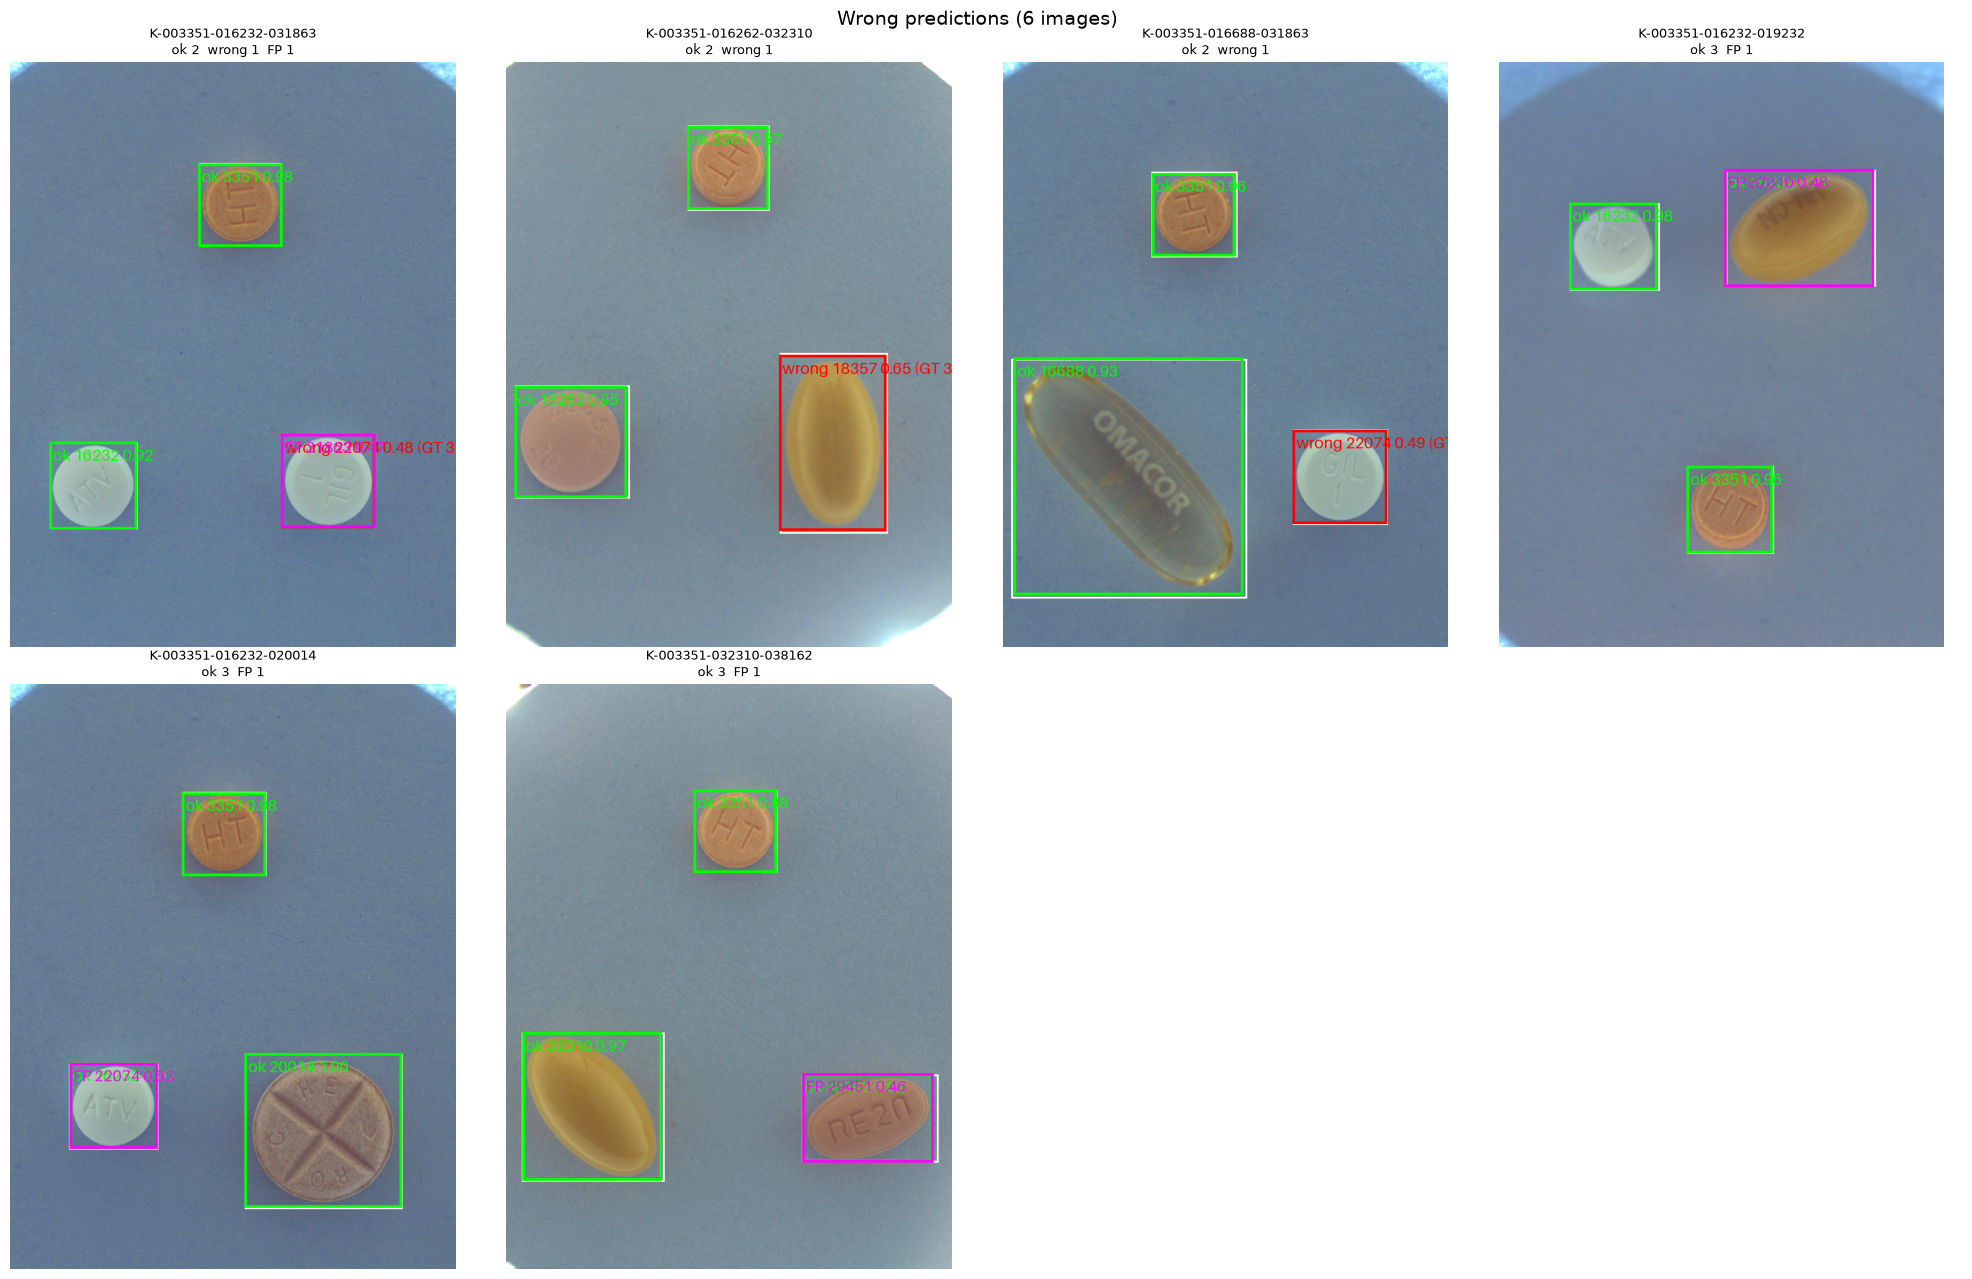

In [51]:
# 2) 잘못 예측한 박스가 있는 사진: 다른 약 → 오검출 → 위치 부정확 순으로 많은 사진부터
wrong_kinds = ["다른 약", "오검출", "위치 부정확"]
wrong = per_image[per_image[wrong_kinds].sum(axis=1) > 0].sort_values(wrong_kinds, ascending=False)
show_cases(wrong.index.tolist(), f"Wrong predictions ({len(wrong)} images)")

In [52]:
# 실패한 박스 목록 (정답 제외). 약 이름을 붙여 어떤 약에서 틀리는지 본다
name_of = class_table.set_index("category_id")["dl_name"]
failures = cases[cases["kind"] != "정답"].assign(
    combo=lambda df: df["file_name"].str.split("_").str[0],
    gt_name=lambda df: df["gt_cid"].map(name_of),
    pred_name=lambda df: df["pred_cid"].map(name_of),
)
failures["kind"] = pd.Categorical(failures["kind"], categories=KINDS)  # 표 순서를 KINDS 순으로
failures = failures.sort_values(["kind", "file_name"])
cols = ["kind", "combo", "file_name", "gt_cid", "gt_name", "pred_cid", "pred_name", "iou", "conf"]
failures[cols].round(3)

,kind,combo,file_name,gt_cid,gt_name,pred_cid,pred_name,iou,conf
28,다른 약,K-003351-016232-031863,K-003351-016232-031863_0_2_0_2_90_000_200.png,31863,아질렉트정(라사길린메실산염),22074,리피로우정 20mg,0.989,0.479
35,다른 약,K-003351-016262-032310,K-003351-016262-032310_0_2_0_2_75_000_200.png,32310,글리아타민연질캡슐,18357,종근당글리아티린연질캡슐(콜린알포세레이트),0.958,0.650
47,다른 약,K-003351-016688-031863,K-003351-016688-031863_0_2_0_2_90_000_200.png,31863,아질렉트정(라사길린메실산염),22074,리피로우정 20mg,0.979,0.489
12,오검출,K-003351-016232-019232,K-003351-016232-019232_0_2_0_2_70_000_200.png,<NA>,NaN,32310,글리아타민연질캡슐,0.000,0.480
25,오검출,K-003351-016232-020014,K-003351-016232-020014_0_2_0_2_90_000_200.png,<NA>,NaN,22074,리피로우정 20mg,0.000,0.632
29,오검출,K-003351-016232-031863,K-003351-016232-031863_0_2_0_2_90_000_200.png,<NA>,NaN,31863,아질렉트정(라사길린메실산염),0.000,0.471
96,오검출,K-003351-032310-038162,K-003351-032310-038162_0_2_0_2_90_000_200.png,<NA>,NaN,29451,레일라정,0.000,0.455
